In [ ]:
import pandas as pd
import numpy as np
import re
import tensorflow as tf

from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model

In [ ]:
# Load your dataset
df = pd.read_csv('/content/eng_-french.csv')

df.columns = ['english', 'french']
print(df.head())

  english      french
0     Hi.      Salut!
1    Run!     Cours !
2    Run!    Courez !
3    Who?       Qui ?
4    Wow!  Ça alors !


In [ ]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-zA-Z?.!,¿]+", " ", text)
    return text.strip()

df['english'] = df['english'].apply(clean_text)
df['french'] = df['french'].apply(clean_text)

In [ ]:
vocab_size = 10000

eng_tokenizer = Tokenizer(num_words=vocab_size, filters='')
fra_tokenizer = Tokenizer(num_words=vocab_size, filters='')

eng_tokenizer.fit_on_texts(df['english'])
fra_tokenizer.fit_on_texts(df['french'])

eng_seq = eng_tokenizer.texts_to_sequences(df['english'])
fra_seq = fra_tokenizer.texts_to_sequences(df['french'])

In [ ]:
max_eng_len = max(len(seq) for seq in eng_seq)
max_fra_len = max(len(seq) for seq in fra_seq)

X = pad_sequences(eng_seq, maxlen=max_eng_len, padding='post')
y = pad_sequences(fra_seq, maxlen=max_fra_len, padding='post')

print(X.shape, y.shape)

(175621, 46) (175621, 59)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
y_train_input = y_train[:, :-1]
y_train_output = y_train[:, 1:]

y_test_input = y_test[:, :-1]
y_test_output = y_test[:, 1:]

In [ ]:
embedding_dim = 256
latent_dim = 256

In [ ]:
# Encoder
encoder_inputs = Input(shape=(max_eng_len,))
enc_emb = Embedding(vocab_size, embedding_dim)(encoder_inputs)

encoder_outputs, state_h, state_c = LSTM(
    latent_dim, return_sequences=True, return_state=True
)(enc_emb)

encoder_states = [state_h, state_c]

# Decoder
decoder_inputs = Input(shape=(max_fra_len - 1,))
dec_emb = Embedding(vocab_size, embedding_dim)(decoder_inputs)

decoder_outputs, _, _ = LSTM(
    latent_dim, return_sequences=True, return_state=True
)(dec_emb, initial_state=encoder_states)

# Attention (IMPORTANT CHANGE)
attention = AdditiveAttention()

context, attn_weights = attention(
    [decoder_outputs, encoder_outputs],
    return_attention_scores=True
)

# Combine
decoder_combined = Concatenate(axis=-1)([decoder_outputs, context])

outputs = Dense(vocab_size, activation='softmax')(decoder_combined)

# Model now outputs BOTH prediction + attention
model = Model([encoder_inputs, decoder_inputs], [outputs, attn_weights])

model.compile(
    optimizer='adam',
    loss=['sparse_categorical_crossentropy', None]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 46)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 58)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 46, 256)   │  2,560,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 58, 256)   │  2,560,000 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ [(None, 46, 256), │    525,312 │ embedding[0][0]   │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ [(None, 58, 256), │    525,312 │ embedding_1[0][0… │
│                     │ (None, 256),      │            │ lstm[0][1],       │
│                     │ (None, 256)]      │            │ lstm[0][2]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ additive_attention  │ [(None, 58, 256), │        256 │ lstm_1[0][0],     │
│ (AdditiveAttention) │ (None, 58, 46)]   │            │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 58, 512)   │          0 │ lstm_1[0][0],     │
│ (Concatenate)       │                   │            │ additive_attenti… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 58, 10000) │  5,130,000 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,300,880 (43.11 MB)

 Trainable params: 11,300,880 (43.11 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    [X_train, y_train_input],
    [y_train_output, np.zeros_like(y_train_output)],
    batch_size=64,
    epochs=10,
    validation_data=(
        [X_test, y_test_input],
        [y_test_output, np.zeros_like(y_test_output)]
    )
)

Epoch 1/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 226s 101ms/step - loss: 0.5833 - val_loss: 0.4000
Epoch 2/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 237s 108ms/step - loss: 0.3040 - val_loss: 0.2551
Epoch 3/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 239s 109ms/step - loss: 0.1999 - val_loss: 0.2080
Epoch 4/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 240s 109ms/step - loss: 0.1536 - val_loss: 0.1906
Epoch 5/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 239s 109ms/step - loss: 0.1264 - val_loss: 0.1831
Epoch 6/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 240s 109ms/step - loss: 0.1076 - val_loss: 0.1804
Epoch 7/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 240s 109ms/step - loss: 0.0936 - val_loss: 0.1803
Epoch 8/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 239s 109ms/step - loss: 0.0825 - val_loss: 0.1825
Epoch 9/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 240s 109ms/step - loss: 0.0737 - val_loss: 0.1849
Epoch 10/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 241s 110ms/step - loss: 0.0665 - val_loss: 0.1887


In [ ]:
reverse_eng = {v:k for k,v in eng_tokenizer.word_index.items()}
reverse_fra = {v:k for k,v in fra_tokenizer.word_index.items()}

In [ ]:
import matplotlib.pyplot as plt

def plot_attention(input_seq, output_seq, attn):
    input_words = [reverse_eng.get(i, '') for i in input_seq if i != 0]
    output_words = [reverse_fra.get(i, '') for i in output_seq if i != 0]

    attn = attn[:len(output_words), :len(input_words)]

    plt.figure(figsize=(6,6))
    plt.imshow(attn, cmap='viridis')

    plt.xticks(range(len(input_words)), input_words, rotation=90)
    plt.yticks(range(len(output_words)), output_words)

    plt.xlabel('English')
    plt.ylabel('French')
    plt.colorbar()
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step


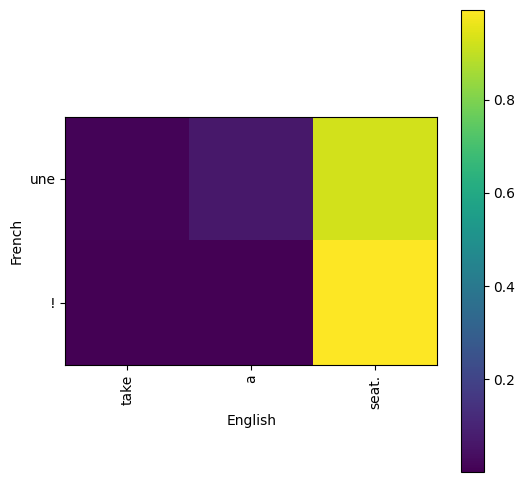

In [ ]:
# Pick one test sample
i = 0

pred, attn = model.predict([X_test[i:i+1], y_test_input[i:i+1]])

pred_seq = np.argmax(pred, axis=-1)[0]

# Plot attention
plot_attention(X_test[i], pred_seq, attn[0])

In [ ]:
# =========================
# LUONG ATTENTION
# =========================

# Encoder
encoder_inputs = Input(shape=(max_eng_len,))
enc_emb = Embedding(vocab_size, embedding_dim)(encoder_inputs)

encoder_outputs, state_h, state_c = LSTM(
    latent_dim, return_sequences=True, return_state=True
)(enc_emb)

encoder_states = [state_h, state_c]

# Decoder
decoder_inputs = Input(shape=(max_fra_len - 1,))
dec_emb = Embedding(vocab_size, embedding_dim)(decoder_inputs)

decoder_outputs, _, _ = LSTM(
    latent_dim, return_sequences=True, return_state=True
)(dec_emb, initial_state=encoder_states)

# Dot Attention
attention = Dot(axes=[2, 2])([decoder_outputs, encoder_outputs])
attention = Activation('softmax')(attention)

context = Dot(axes=[2,1])([attention, encoder_outputs])

decoder_combined = Concatenate(axis=-1)([decoder_outputs, context])

outputs = Dense(vocab_size, activation='softmax')(decoder_combined)

model_luong = Model([encoder_inputs, decoder_inputs], outputs)

model_luong.compile(optimizer='adam', loss='sparse_categorical_crossentropy')

model_luong.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 46)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_3       │ (None, 58)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 46, 256)   │  2,560,000 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 58, 256)   │  2,560,000 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ [(None, 46, 256), │    525,312 │ embedding_2[0][0] │
│                     │ (None, 256),      │            │                   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_3 (LSTM)       │ [(None, 58, 256), │    525,312 │ embedding_3[0][0… │
│                     │ (None, 256),      │            │ lstm_2[0][1],     │
│                     │ (None, 256)]      │            │ lstm_2[0][2]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dot (Dot)           │ (None, 58, 46)    │          0 │ lstm_3[0][0],     │
│                     │                   │            │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 58, 46)    │          0 │ dot[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dot_1 (Dot)         │ (None, 58, 256)   │          0 │ activation[0][0], │
│                     │                   │            │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 58, 512)   │          0 │ lstm_3[0][0],     │
│ (Concatenate)       │                   │            │ dot_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 58, 10000) │  5,130,000 │ concatenate_1[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,300,624 (43.11 MB)

 Trainable params: 11,300,624 (43.11 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_luong = model_luong.fit(
    [X_train, y_train_input],
    y_train_output,
    batch_size=64,
    epochs=10,
    validation_data=([X_test, y_test_input], y_test_output)
)

Epoch 1/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 195s 88ms/step - loss: 0.6042 - val_loss: 0.4467
Epoch 2/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 193s 88ms/step - loss: 0.3574 - val_loss: 0.2985
Epoch 3/10
2196/2196 ━━━━━━━━━━━━━━━━━━━━ 193s 88ms/step - loss: 0.2375 - val_loss: 0.2319
Epoch 4/10
1490/2196 ━━━━━━━━━━━━━━━━━━━━ 57s 81ms/step - loss: 0.1825

In [ ]:
# =========================
# CROSS ATTENTION
# =========================

from tensorflow.keras.layers import MultiHeadAttention

# Encoder
encoder_inputs = Input(shape=(max_eng_len,))
enc_emb = Embedding(vocab_size, embedding_dim)(encoder_inputs)

encoder_outputs, state_h, state_c = LSTM(
    latent_dim, return_sequences=True, return_state=True
)(enc_emb)

encoder_states = [state_h, state_c]

# Decoder
decoder_inputs = Input(shape=(max_fra_len - 1,))
dec_emb = Embedding(vocab_size, embedding_dim)(decoder_inputs)

decoder_outputs, _, _ = LSTM(
    latent_dim, return_sequences=True, return_state=True
)(dec_emb, initial_state=encoder_states)

# Cross Attention
mha = MultiHeadAttention(num_heads=4, key_dim=latent_dim)

attn_output = mha(
    query=decoder_outputs,
    value=encoder_outputs,
    key=encoder_outputs
)

decoder_combined = Concatenate(axis=-1)([decoder_outputs, attn_output])

outputs = Dense(vocab_size, activation='softmax')(decoder_combined)

model_cross = Model([encoder_inputs, decoder_inputs], outputs)

model_cross.compile(optimizer='adam', loss='sparse_categorical_crossentropy')

model_cross.summary()

In [ ]:
history_cross = model_cross.fit(
    [X_train, y_train_input],
    y_train_output,
    batch_size=64,
    epochs=10,
    validation_data=([X_test, y_test_input], y_test_output)
)

In [ ]:
from nltk.translate.bleu_score import sentence_bleu

def evaluate_bleu(model):
    scores = []
    for i in range(10):
        pred = model.predict([X_test[i:i+1], y_test_input[i:i+1]])
        pred_seq = np.argmax(pred, axis=-1)[0]

        reference = [y_test[i]]
        candidate = pred_seq

        score = sentence_bleu(reference, candidate)
        scores.append(score)

    print("BLEU:", np.mean(scores))

evaluate_bleu(model_soft)
evaluate_bleu(model_luong)
evaluate_bleu(model_cross)

In [ ]:
# Convert token sequence → sentence
def seq_to_sentence(seq, tokenizer):
    reverse_map = {v: k for k, v in tokenizer.word_index.items()}

    words = []
    for i in seq:
        if i == 0:
            continue
        word = reverse_map.get(i, '')
        if word:
            words.append(word)

    return ' '.join(words)

In [ ]:
def compare_models(idx):
    x = X_test[idx:idx+1]
    y_in = y_test_input[idx:idx+1]

    pred_soft = model_soft.predict([x, y_in], verbose=0)
    pred_luong = model_luong.predict([x, y_in], verbose=0)
    pred_cross = model_cross.predict([x, y_in], verbose=0)

    pred_soft = np.argmax(pred_soft, axis=-1)[0]
    pred_luong = np.argmax(pred_luong, axis=-1)[0]
    pred_cross = np.argmax(pred_cross, axis=-1)[0]

    print("ENGLISH :", seq_to_sentence(X_test[idx], eng_tokenizer))
    print("ACTUAL  :", seq_to_sentence(y_test[idx], fra_tokenizer))
    print("SOFT    :", seq_to_sentence(pred_soft, fra_tokenizer))
    print("LUONG   :", seq_to_sentence(pred_luong, fra_tokenizer))
    print("CROSS   :", seq_to_sentence(pred_cross, fra_tokenizer))
    print("=" * 60)

In [ ]:
import random
for idx in random.sample(range(len(X_test)), 10):
    compare_models(idx)